<a href="https://colab.research.google.com/github/mohammad-mustafa130/Alzheimers-MRI-Classification/blob/main/Alzheimers_MRI_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import os

print("Alzheimer MRI Classification Project")
print("------------------------------------")

print("Python Version:", sys.version)
print("Current Directory:", os.getcwd())

# Check TensorFlow installation
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

# Check GPU availability
print("Available GPU:", tf.config.list_physical_devices('GPU'))


Alzheimer MRI Classification Project
------------------------------------
Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Current Directory: /content
TensorFlow Version: 2.21.0
Available GPU: []


In [2]:

from google.colab import drive

# Connect Google Drive with Colab
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

import os

dataset_folder = "/content/drive/MyDrive/Alzheimers_MRI_Project/dataset"

print("Files inside dataset folder:")

for file in os.listdir(dataset_folder):
    print(file)


Files inside dataset folder:
Alzheimer (Preprocessed Data).zip


In [4]:

import zipfile
import os

zip_path = os.path.join(
    dataset_folder,
    "Alzheimer (Preprocessed Data).zip"
)

extract_path = "/content/alzheimers_dataset"

# Extract dataset
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Extraction location:", extract_path)


Dataset extracted successfully!
Extraction location: /content/alzheimers_dataset


In [5]:
import os

dataset_path = "/content/alzheimers_dataset"

print("DATASET FOLDER STRUCTURE")
print("========================")

# Check whether the extraction folder exists
print("Folder exists:", os.path.exists(dataset_path))

# Display files and folders
print("\nContents of extraction folder:")

for item in os.listdir(dataset_path):
    item_path = os.path.join(dataset_path, item)

    if os.path.isdir(item_path):
        print("📁 Folder:", item)
    else:
        print("📄 File:", item)

DATASET FOLDER STRUCTURE
Folder exists: True

Contents of extraction folder:
📁 Folder: Alzheimer (Preprocessed Data)


In [6]:
import os

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

print("INSIDE ALZHEIMER DATASET")
print("========================")

for item in os.listdir(dataset_path):
    item_path = os.path.join(dataset_path, item)

    if os.path.isdir(item_path):
        print("📁 Folder:", item)
    else:
        print("📄 File:", item)

INSIDE ALZHEIMER DATASET
📁 Folder: Moderate_Demented
📁 Folder: Very_Mild_Demented
📁 Folder: Mild_Demented
📁 Folder: Non_Demented


In [7]:
import os

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

print("NUMBER OF IMAGES IN EACH CLASS")
print("--------------------------------")

total_images = 0

for class_name in os.listdir(dataset_path):

    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):

        images = os.listdir(class_path)

        image_count = len(images)

        total_images += image_count

        print(class_name, ":", image_count)

print("--------------------------------")
print("Total Images:", total_images)

NUMBER OF IMAGES IN EACH CLASS
--------------------------------
Moderate_Demented : 64
Very_Mild_Demented : 2240
Mild_Demented : 896
Non_Demented : 3200
--------------------------------
Total Images: 6400


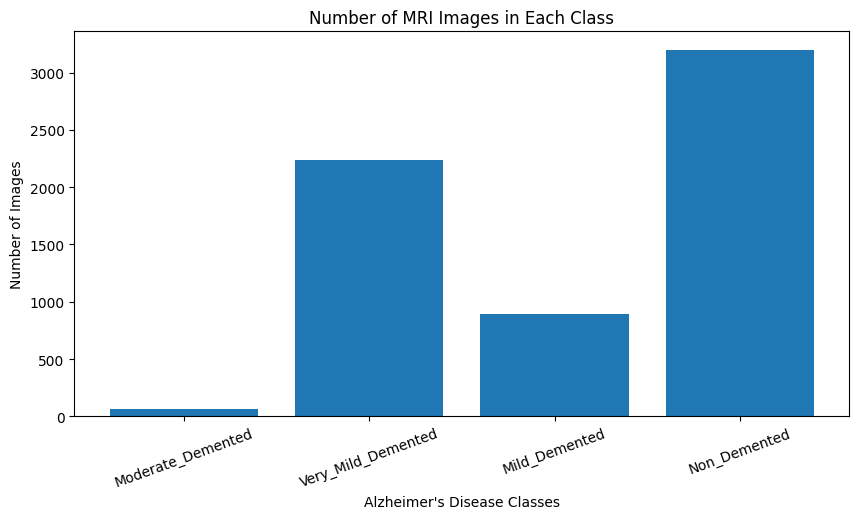

In [8]:
import os
import matplotlib.pyplot as plt

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

class_names = []
image_counts = []

for class_name in os.listdir(dataset_path):

    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):

        count = len(os.listdir(class_path))

        class_names.append(class_name)
        image_counts.append(count)

# Create bar chart
plt.figure(figsize=(10, 5))

plt.bar(class_names, image_counts)

plt.title("Number of MRI Images in Each Class")
plt.xlabel("Alzheimer's Disease Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=20)
plt.show()

In [9]:
import os
import numpy as np
from PIL import Image

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

class_names = [
    "Non_Demented",
    "Very_Mild_Demented",
    "Mild_Demented",
    "Moderate_Demented"
]

print("MRI PIXEL VALUE INSPECTION")
print("==========================")

for class_name in class_names:

    class_path = os.path.join(dataset_path, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    image_path = os.path.join(class_path, image_files[0])

    image = Image.open(image_path)

    image_array = np.array(image)

    print("\nClass:", class_name)
    print("Image shape:", image_array.shape)
    print("Data type:", image_array.dtype)
    print("Minimum pixel value:", np.min(image_array))
    print("Maximum pixel value:", np.max(image_array))
    print("Average pixel value:", np.mean(image_array))

MRI PIXEL VALUE INSPECTION

Class: Non_Demented
Image shape: (128, 128)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 254
Average pixel value: 78.60406494140625

Class: Very_Mild_Demented
Image shape: (128, 128)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Average pixel value: 70.36846923828125

Class: Mild_Demented
Image shape: (128, 128)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Average pixel value: 58.74395751953125

Class: Moderate_Demented
Image shape: (128, 128)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 252
Average pixel value: 60.9266357421875


In [10]:
import os
import numpy as np
from PIL import Image

# Select the Non_Demented class
class_path = os.path.join(dataset_path, "Non_Demented")

# Get the first image filename
image_name = os.listdir(class_path)[0]

# Create the complete image path
image_path = os.path.join(class_path, image_name)

# Open the MRI image
image = Image.open(image_path)

# Convert image into a NumPy array
image_array = np.array(image)

# Normalize pixel values
normalized_image = image_array.astype("float32") / 255.0

# Compare original and normalized images
print("BEFORE NORMALIZATION")
print("Data type:", image_array.dtype)
print("Minimum:", image_array.min())
print("Maximum:", image_array.max())

print("\nAFTER NORMALIZATION")
print("Data type:", normalized_image.dtype)
print("Minimum:", normalized_image.min())
print("Maximum:", normalized_image.max())

print("\nFirst 10 original pixel values:")
print(image_array[64, :10])

print("\nFirst 10 normalized pixel values:")
print(normalized_image[64, :10])

BEFORE NORMALIZATION
Data type: uint8
Minimum: 0
Maximum: 254

AFTER NORMALIZATION
Data type: float32
Minimum: 0.0
Maximum: 0.99607843

First 10 original pixel values:
[0 0 0 0 0 0 0 0 0 0]

First 10 normalized pixel values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [14]:
variables = [
    "image_paths",
    "labels",
    "train_paths",
    "train_labels",
    "val_paths",
    "val_labels",
    "test_paths",
    "test_labels",
    "train_labels_encoded",
    "val_labels_encoded",
    "test_labels_encoded",
    "train_dataset",
    "load_image"
]

for variable in variables:
    print(variable, ":", variable in globals())

image_paths : False
labels : False
train_paths : False
train_labels : False
val_paths : False
val_labels : False
test_paths : False
test_labels : False
train_labels_encoded : False
val_labels_encoded : False
test_labels_encoded : False
train_dataset : False
load_image : False


In [15]:
import os

# Location of our MRI dataset
dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

# Our four Alzheimer's classes
class_names = [
    "Non_Demented",
    "Very_Mild_Demented",
    "Mild_Demented",
    "Moderate_Demented"
]

# Empty lists for image paths and labels
image_paths = []
labels = []

# Read all MRI image paths
for class_name in class_names:

    class_path = os.path.join(dataset_path, class_name)

    for filename in sorted(os.listdir(class_path)):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            image_paths.append(
                os.path.join(class_path, filename)
            )

            labels.append(class_name)

print("IMAGE PATHS RESTORED")
print("====================")
print("Total image paths:", len(image_paths))
print("Total labels:", len(labels))

IMAGE PATHS RESTORED
Total image paths: 6400
Total labels: 6400


In [16]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: divide temporary data equally
# 15% validation and 15% testing
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("DATASET SPLIT RESTORED")
print("======================")
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))
print("Total images:",
      len(train_paths) + len(val_paths) + len(test_paths))

DATASET SPLIT RESTORED
Training images: 4480
Validation images: 960
Testing images: 960
Total images: 6400


In [17]:
# Define the class-to-number mapping
class_to_index = {
    "Non_Demented": 0,
    "Very_Mild_Demented": 1,
    "Mild_Demented": 2,
    "Moderate_Demented": 3
}

# Encode training labels
train_labels_encoded = [
    class_to_index[label] for label in train_labels
]

# Encode validation labels
val_labels_encoded = [
    class_to_index[label] for label in val_labels
]

# Encode testing labels
test_labels_encoded = [
    class_to_index[label] for label in test_labels
]

print("NUMERICAL LABELS RESTORED")
print("=========================")

print("Training labels:", len(train_labels_encoded))
print("Validation labels:", len(val_labels_encoded))
print("Testing labels:", len(test_labels_encoded))

print("\nFirst 5 original labels:", train_labels[:5])
print("First 5 encoded labels:", train_labels_encoded[:5])

NUMERICAL LABELS RESTORED
Training labels: 4480
Validation labels: 960
Testing labels: 960

First 5 original labels: ['Very_Mild_Demented', 'Moderate_Demented', 'Non_Demented', 'Very_Mild_Demented', 'Non_Demented']
First 5 encoded labels: [1, 3, 0, 1, 0]


In [18]:
import tensorflow as tf

def load_image(image_path, label):

    # Read the MRI image file
    image = tf.io.read_file(image_path)

    # Decode JPEG image as grayscale
    image = tf.image.decode_jpeg(image, channels=1)

    # Normalize pixel values from 0–255 to 0–1
    image = tf.image.convert_image_dtype(image, tf.float32)

    # Ensure the expected CNN input shape
    image = tf.ensure_shape(image, [128, 128, 1])

    return image, label

print("Image-loading function restored successfully!")

Image-loading function restored successfully!


In [19]:
# Create training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels_encoded)
)

# Create validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels_encoded)
)

# Create testing dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels_encoded)
)

print("TENSORFLOW DATASETS RESTORED")
print("============================")
print("Training images:", train_dataset.cardinality().numpy())
print("Validation images:", val_dataset.cardinality().numpy())
print("Testing images:", test_dataset.cardinality().numpy())

TENSORFLOW DATASETS RESTORED
Training images: 4480
Validation images: 960
Testing images: 960


In [20]:
# Apply preprocessing to the training dataset
train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Apply preprocessing to the validation dataset
val_dataset = val_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Apply preprocessing to the testing dataset
test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("IMAGE PREPROCESSING APPLIED")
print("===========================")

# Inspect one processed training image
for image, label in train_dataset.take(1):

    print("Image shape:", image.shape)
    print("Image data type:", image.dtype)
    print("Minimum pixel value:", tf.reduce_min(image).numpy())
    print("Maximum pixel value:", tf.reduce_max(image).numpy())
    print("Encoded label:", label.numpy())

IMAGE PREPROCESSING APPLIED
Image shape: (128, 128, 1)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 0.9843138
Encoded label: 1


In [21]:
# Define batch size
BATCH_SIZE = 32

# Organize datasets into batches
train_dataset = train_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)

print("BATCHING COMPLETED")
print("==================")

# Inspect one training batch
for images, labels in train_dataset.take(1):

    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Labels:", labels.numpy())

BATCHING COMPLETED
Batch image shape: (32, 128, 128, 1)
Batch label shape: (32,)
Image data type: <dtype: 'float32'>
Labels: [1 3 0 1 0 0 2 2 0 0 0 1 1 1 1 0 1 0 0 0 0 0 0 0 0 0 2 0 1 0 0 0]


In [22]:
# Recreate the training dataset from paths and labels
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels_encoded)
)

# Shuffle training examples
train_dataset = train_dataset.shuffle(
    buffer_size=len(train_paths),
    seed=42,
    reshuffle_each_iteration=True
)

# Load and normalize MRI images
train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Group images into batches
train_dataset = train_dataset.batch(32)

print("TRAINING DATASET SHUFFLED SUCCESSFULLY")
print("======================================")

# Inspect the first batch
for images, labels in train_dataset.take(1):
    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels.shape)
    print("First 10 labels:", labels.numpy()[:10])

TRAINING DATASET SHUFFLED SUCCESSFULLY
Batch image shape: (32, 128, 128, 1)
Batch label shape: (32,)
First 10 labels: [0 1 0 0 0 0 0 2 0 1]


In [23]:
# Enable automatic prefetch optimization
AUTOTUNE = tf.data.AUTOTUNE

# Apply prefetching to all three datasets
train_dataset = train_dataset.prefetch(AUTOTUNE)
val_dataset = val_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

print("PREFETCHING COMPLETED")
print("=====================")

print("Training batches:", train_dataset.cardinality().numpy())
print("Validation batches:", val_dataset.cardinality().numpy())
print("Testing batches:", test_dataset.cardinality().numpy())

PREFETCHING COMPLETED
Training batches: 140
Validation batches: 30
Testing batches: 30


In [24]:
from tensorflow.keras import layers, models

# Create our CNN model
model = models.Sequential([

    # Input layer
    layers.Input(shape=(128, 128, 1)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a feature vector
    layers.GlobalAveragePooling2D(),

    # Fully connected layer
    layers.Dense(64, activation="relu"),

    # Reduce overfitting
    layers.Dropout(0.3),

    # Output layer for 4 Alzheimer's classes
    layers.Dense(4, activation="softmax")
])

print("CNN MODEL CREATED SUCCESSFULLY")

CNN MODEL CREATED SUCCESSFULLY


In [25]:
# Display the complete CNN architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,188 (395.27 KB)

 Trainable params: 101,188 (395.27 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# Compile the CNN model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN MODEL COMPILED SUCCESSFULLY")

CNN MODEL COMPILED SUCCESSFULLY


In [27]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Four numerical classes
classes = np.array([0, 1, 2, 3])

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=np.array(train_labels_encoded)
)

# Convert weights into a dictionary
class_weights = dict(zip(classes.tolist(), weights.tolist()))

print("CLASS WEIGHTS CALCULATED")
print("========================")

for class_index, weight in class_weights.items():
    print(
        class_names[class_index],
        ":", round(weight, 4)
    )

CLASS WEIGHTS CALCULATED
Non_Demented : 0.5
Very_Mild_Demented : 0.7143
Mild_Demented : 1.7863
Moderate_Demented : 24.8889


In [28]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import os

# Create a folder in Google Drive for saved models
model_save_dir = "/content/drive/MyDrive/Alzheimers_MRI_Project/models"

os.makedirs(model_save_dir, exist_ok=True)

# Define where the best model will be saved
model_save_path = os.path.join(
    model_save_dir,
    "best_custom_cnn.keras"
)

# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Save the model whenever validation loss improves
model_checkpoint = ModelCheckpoint(
    filepath=model_save_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Store both callbacks together
callbacks = [early_stopping, model_checkpoint]

print("TRAINING CALLBACKS CONFIGURED")
print("=============================")
print("Model save path:", model_save_path)
print("Early stopping patience:", early_stopping.patience)
print("Number of callbacks:", len(callbacks))

TRAINING CALLBACKS CONFIGURED
Model save path: /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn.keras
Early stopping patience: 5
Number of callbacks: 2


In [ ]:
# Check that Google Drive is mounted
import os

assert os.path.ismount("/content/drive"), "Please mount Google Drive first."

# Set the maximum number of training epochs
EPOCHS = 15

# Train our custom CNN
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

print("CNN TRAINING COMPLETED")

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 671ms/step - accuracy: 0.2878 - loss: 1.3740
Epoch 1: val_loss improved from None to 1.38471, saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 106s 746ms/step - accuracy: 0.2199 - loss: 1.3996 - val_accuracy: 0.1677 - val_loss: 1.3847
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 684ms/step - accuracy: 0.2960 - loss: 1.2948
Epoch 2: val_loss did not improve from 1.38471
140/140 ━━━━━━━━━━━━━━━━━━━━ 106s 758ms/step - accuracy: 0.2643 - loss: 1.3886 - val_accuracy: 0.0104 - val_loss: 1.3879
Epoch 3/15
 66/140 ━━━━━━━━━━━━━━━━━━━━ 50s 680ms/step - accuracy: 0.0444 - loss: 1.4934

In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os

print("TRAINING RECOVERY CHECK")
print("=======================")

# Check important Python variables
print("Model variable:", "model" in globals())
print("Training dataset:", "train_dataset" in globals())
print("Validation dataset:", "val_dataset" in globals())
print("Class weights:", "class_weights" in globals())

# Check Google Drive
print("\nGOOGLE DRIVE CHECK")
print("==================")

print("Drive mounted:", os.path.ismount("/content/drive"))

# Location of the saved model
model_path = "/content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn.keras"

print("Saved model exists:", os.path.isfile(model_path))

TRAINING RECOVERY CHECK
Model variable: False
Training dataset: False
Validation dataset: False
Class weights: False

GOOGLE DRIVE CHECK
Drive mounted: False
Saved model exists: False


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

model_path = "/content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn.keras"

print("Google Drive mounted:", os.path.ismount("/content/drive"))
print("Saved CNN model exists:", os.path.isfile(model_path))

Google Drive mounted: True
Saved CNN model exists: True


In [5]:
import tensorflow as tf

# Location of our saved CNN model
model_path = "/content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn.keras"

# Load the previously saved model
model = tf.keras.models.load_model(model_path)

print("SAVED CNN MODEL LOADED SUCCESSFULLY")
print("===================================")

# Display the restored architecture
model.summary()

SAVED CNN MODEL LOADED SUCCESSFULLY


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 303,566 (1.16 MB)

 Trainable params: 101,188 (395.27 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 202,378 (790.54 KB)

In [6]:
import os

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

print("DATASET RECOVERY CHECK")
print("======================")

print("Dataset folder exists:", os.path.isdir(dataset_path))

if os.path.isdir(dataset_path):
    print("\nClass folders:")
    for folder in sorted(os.listdir(dataset_path)):
        print(folder)

DATASET RECOVERY CHECK
Dataset folder exists: False


In [7]:
import os

# Location of the original dataset ZIP file
zip_path = "/content/drive/MyDrive/Alzheimers_MRI_Project/dataset/Alzheimer (Preprocessed Data).zip"

print("DATASET ZIP CHECK")
print("=================")

print("ZIP file exists:", os.path.isfile(zip_path))

if os.path.isfile(zip_path):
    print("ZIP file size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))

DATASET ZIP CHECK
ZIP file exists: True
ZIP file size (MB): 28.46


In [8]:
import os
import zipfile

# Original ZIP file in Google Drive
zip_path = "/content/drive/MyDrive/Alzheimers_MRI_Project/dataset/Alzheimer (Preprocessed Data).zip"

# Destination folder in Colab
extract_path = "/content/alzheimers_dataset"

# Create destination folder
os.makedirs(extract_path, exist_ok=True)

# Extract the ZIP file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("MRI DATASET EXTRACTED SUCCESSFULLY")
print("==================================")

# Define dataset location
dataset_path = os.path.join(
    extract_path,
    "Alzheimer (Preprocessed Data)"
)

print("Dataset folder exists:", os.path.isdir(dataset_path))

# Check class folders and image counts
if os.path.isdir(dataset_path):
    total_images = 0

    for class_name in sorted(os.listdir(dataset_path)):
        class_path = os.path.join(dataset_path, class_name)

        if os.path.isdir(class_path):
            count = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])

            print(class_name, ":", count)
            total_images += count

    print("\nTotal MRI images:", total_images)

MRI DATASET EXTRACTED SUCCESSFULLY
Dataset folder exists: True
Mild_Demented : 896
Moderate_Demented : 64
Non_Demented : 3200
Very_Mild_Demented : 2240

Total MRI images: 6400


In [9]:
import os
from sklearn.model_selection import train_test_split

# Keep the same class order as before
class_names = [
    "Non_Demented",
    "Very_Mild_Demented",
    "Mild_Demented",
    "Moderate_Demented"
]

# Create lists for image paths and labels
image_paths = []
labels = []

# Collect all image paths
for class_name in class_names:

    class_path = os.path.join(dataset_path, class_name)

    for filename in sorted(os.listdir(class_path)):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            image_paths.append(
                os.path.join(class_path, filename)
            )

            labels.append(class_name)

# First split: 70% training, 30% temporary
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: 15% validation, 15% testing
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("DATASET SPLIT RESTORED")
print("======================")

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

print("\nFirst 3 training labels:", train_labels[:3])

DATASET SPLIT RESTORED
Training images: 4480
Validation images: 960
Testing images: 960

First 3 training labels: ['Very_Mild_Demented', 'Moderate_Demented', 'Non_Demented']


In [10]:
# Restore the original class mapping
class_to_index = {
    "Non_Demented": 0,
    "Very_Mild_Demented": 1,
    "Mild_Demented": 2,
    "Moderate_Demented": 3
}

# Convert training labels into numbers
train_labels_encoded = [
    class_to_index[label] for label in train_labels
]

# Convert validation labels into numbers
val_labels_encoded = [
    class_to_index[label] for label in val_labels
]

# Convert testing labels into numbers
test_labels_encoded = [
    class_to_index[label] for label in test_labels
]

print("NUMERICAL LABELS RESTORED")
print("=========================")

print("Training labels:", len(train_labels_encoded))
print("Validation labels:", len(val_labels_encoded))
print("Testing labels:", len(test_labels_encoded))

print("\nFirst 5 encoded training labels:")
print(train_labels_encoded[:5])

NUMERICAL LABELS RESTORED
Training labels: 4480
Validation labels: 960
Testing labels: 960

First 5 encoded training labels:
[1, 3, 0, 1, 0]


In [11]:
import tensorflow as tf

# Function to load and preprocess one MRI image
def load_image(image_path, label):

    # Read the image file
    image = tf.io.read_file(image_path)

    # Decode JPEG as a grayscale image
    image = tf.image.decode_jpeg(image, channels=1)

    # Normalize pixel values to the range 0–1
    image = tf.image.convert_image_dtype(image, tf.float32)

    # Ensure the correct CNN input shape
    image = tf.ensure_shape(image, [128, 128, 1])

    # Return processed image and its label
    return image, label


print("MRI IMAGE-LOADING FUNCTION RESTORED")
print("===================================")

# Test the function on one validation image
sample_image, sample_label = load_image(
    val_paths[0],
    val_labels_encoded[0]
)

print("Image shape:", sample_image.shape)
print("Image data type:", sample_image.dtype)
print("Minimum pixel value:", tf.reduce_min(sample_image).numpy())
print("Maximum pixel value:", tf.reduce_max(sample_image).numpy())
print("Encoded label:", sample_label)

MRI IMAGE-LOADING FUNCTION RESTORED
Image shape: (128, 128, 1)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Encoded label: 1


In [12]:
import tensorflow as tf

BATCH_SIZE = 32

# Create the validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels_encoded)
)

# Load and preprocess the MRI images
val_dataset = val_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Group images into batches
val_dataset = val_dataset.batch(BATCH_SIZE)

# Improve data-loading performance
val_dataset = val_dataset.prefetch(tf.data.AUTOTUNE)

print("VALIDATION DATASET RESTORED")
print("===========================")

print("Number of validation images:", len(val_paths))
print("Batch size:", BATCH_SIZE)
print("Number of batches:", len(val_dataset))

# Inspect the first batch
for images, labels in val_dataset.take(1):
    print("\nFirst batch image shape:", images.shape)
    print("First batch label shape:", labels.shape)
    print("First 5 labels:", labels[:5].numpy())

VALIDATION DATASET RESTORED
Number of validation images: 960
Batch size: 32
Number of batches: 30

First batch image shape: (32, 128, 128, 1)
First batch label shape: (32,)
First 5 labels: [1 1 0 0 1]


In [13]:
import numpy as np
from collections import Counter

# Predict using the recovered CNN model
predicted_probabilities = model.predict(
    val_dataset,
    verbose=1
)

# Convert probabilities into predicted class indices
predicted_labels = np.argmax(
    predicted_probabilities,
    axis=1
)

# Count predictions for each class
prediction_counts = Counter(predicted_labels)

print("\nCNN PREDICTION DISTRIBUTION")
print("===========================")

for class_index, class_name in enumerate(class_names):
    count = prediction_counts.get(class_index, 0)

    print(f"{class_name}: {count}")

print("\nTotal predictions:", len(predicted_labels))

# Calculate validation accuracy
actual_labels = np.array(val_labels_encoded)

validation_accuracy = np.mean(
    predicted_labels == actual_labels
)

print(
    "Validation accuracy:",
    round(validation_accuracy * 100, 2),
    "%"
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step

CNN PREDICTION DISTRIBUTION
Non_Demented: 0
Very_Mild_Demented: 0
Mild_Demented: 960
Moderate_Demented: 0

Total predictions: 960
Validation accuracy: 13.96 %


In [14]:
import numpy as np

print("CNN PREDICTION CONFIDENCE ANALYSIS")
print("==================================")

# Average predicted probability for each class
average_probabilities = np.mean(
    predicted_probabilities,
    axis=0
)

for class_name, probability in zip(
    class_names,
    average_probabilities
):
    print(f"{class_name}: {probability * 100:.2f}%")

# Confidence of the winning class for each image
confidence_scores = np.max(
    predicted_probabilities,
    axis=1
)

print("\nCONFIDENCE STATISTICS")
print("=====================")

print(
    "Minimum confidence:",
    round(np.min(confidence_scores) * 100, 2), "%"
)

print(
    "Average confidence:",
    round(np.mean(confidence_scores) * 100, 2), "%"
)

print(
    "Maximum confidence:",
    round(np.max(confidence_scores) * 100, 2), "%"
)

print("\nFirst 5 prediction probability vectors:")
print(np.round(predicted_probabilities[:5], 4))

CNN PREDICTION CONFIDENCE ANALYSIS
Non_Demented: 25.26%
Very_Mild_Demented: 24.90%
Mild_Demented: 25.90%
Moderate_Demented: 23.94%

CONFIDENCE STATISTICS
Minimum confidence: 25.68 %
Average confidence: 25.9 %
Maximum confidence: 25.96 %

First 5 prediction probability vectors:
[[0.2527 0.249  0.2592 0.2391]
 [0.2526 0.249  0.2591 0.2393]
 [0.2527 0.249  0.2592 0.239 ]
 [0.2526 0.249  0.2591 0.2393]
 [0.2526 0.249  0.2589 0.2394]]


In [15]:
# Create the training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels_encoded)
)

# Shuffle training images
train_dataset = train_dataset.shuffle(
    buffer_size=len(train_paths),
    seed=42,
    reshuffle_each_iteration=True
)

# Load and normalize MRI images
train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Group images into batches
train_dataset = train_dataset.batch(BATCH_SIZE)

# Prepare upcoming batches
train_dataset = train_dataset.prefetch(
    tf.data.AUTOTUNE
)

print("TRAINING DATASET RESTORED")
print("=========================")

print("Training images:", len(train_paths))
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_dataset))

# Verify the first batch
for images, labels in train_dataset.take(1):
    print("\nImage batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

TRAINING DATASET RESTORED
Training images: 4480
Batch size: 32
Training batches: 140

Image batch shape: (32, 128, 128, 1)
Label batch shape: (32,)
Pixel range: 0.0 to 1.0


In [16]:
import numpy as np
from collections import Counter

# Count images in each training class
class_counts = Counter(train_labels_encoded)

# Calculate balanced class weights
total_samples = len(train_labels_encoded)
num_classes = len(class_names)

balanced_weights = {
    i: total_samples / (num_classes * class_counts[i])
    for i in range(num_classes)
}

# Reduce extreme weights using square root
class_weights_v2 = {
    i: float(np.sqrt(balanced_weights[i]))
    for i in range(num_classes)
}

print("IMPROVED CLASS WEIGHTS")
print("======================")

for i, class_name in enumerate(class_names):
    print(
        f"{class_name}: "
        f"{class_counts[i]} images, "
        f"weight = {class_weights_v2[i]:.4f}"
    )

IMPROVED CLASS WEIGHTS
Non_Demented: 2240 images, weight = 0.7071
Very_Mild_Demented: 1568 images, weight = 0.8452
Mild_Demented: 627 images, weight = 1.3365
Moderate_Demented: 45 images, weight = 4.9889


In [17]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Create a fresh CNN model (Version 2)
model_v2 = models.Sequential([

    layers.Input(shape=(128, 128, 1)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(4, activation="softmax")
])

# Compile with a lower learning rate
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("IMPROVED CNN MODEL CREATED")
print("==========================")

model_v2.summary()

IMPROVED CNN MODEL CREATED


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,188 (395.27 KB)

 Trainable params: 101,188 (395.27 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
import os
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

# Folder for saved models in Google Drive
model_save_dir = "/content/drive/MyDrive/Alzheimers_MRI_Project/models"

os.makedirs(model_save_dir, exist_ok=True)

# Separate checkpoint for CNN Version 2
model_v2_save_path = os.path.join(
    model_save_dir,
    "best_custom_cnn_v2.keras"
)

# Stop if validation loss stops improving
early_stopping_v2 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Save the best model to Google Drive
model_checkpoint_v2 = ModelCheckpoint(
    filepath=model_v2_save_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Combine callbacks
callbacks_v2 = [
    early_stopping_v2,
    model_checkpoint_v2
]

print("CNN VERSION 2 CALLBACKS CONFIGURED")
print("==================================")

print("Model save path:", model_v2_save_path)
print("Early stopping patience:", 5)
print("Checkpoint monitoring:", "val_loss")
print("Original CNN checkpoint preserved:",
      os.path.isfile(os.path.join(
          model_save_dir,
          "best_custom_cnn.keras"
      )))

CNN VERSION 2 CALLBACKS CONFIGURED
Model save path: /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v2.keras
Early stopping patience: 5
Checkpoint monitoring: val_loss
Original CNN checkpoint preserved: True


In [19]:
# Train CNN Version 2
history_v2 = model_v2.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    class_weight=class_weights_v2,
    callbacks=callbacks_v2,
    verbose=1
)

print("\nCNN VERSION 2 TRAINING FINISHED")
print("==============================")

print("Epochs completed:", len(history_v2.history["loss"]))

print(
    "Best validation accuracy:",
    round(max(history_v2.history["val_accuracy"]) * 100, 2),
    "%"
)

print(
    "Best validation loss:",
    round(min(history_v2.history["val_loss"]), 4)
)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.4393 - loss: 1.1163
Epoch 1: val_loss improved from None to 1.11460, saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v2.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 39ms/step - accuracy: 0.4605 - loss: 1.1086 - val_accuracy: 0.5000 - val_loss: 1.1146
Epoch 2/15
139/140 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4863 - loss: 1.0593
Epoch 2: val_loss improved from 1.11460 to 1.09633, saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v2.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v2.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.4853 - loss: 1.0956 - val_accuracy: 0.5000 - val_loss: 1.0963
Epoch 3/15
139/140 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4812 - 

In [20]:
import numpy as np
from collections import Counter

# Predict all validation MRI images
predicted_probabilities_v2 = model_v2.predict(
    val_dataset,
    verbose=1
)

# Convert probabilities into class labels
predicted_labels_v2 = np.argmax(
    predicted_probabilities_v2,
    axis=1
)

# Count predicted classes
prediction_counts_v2 = Counter(predicted_labels_v2)

print("\nCNN VERSION 2 PREDICTION DISTRIBUTION")
print("=====================================")

for i, class_name in enumerate(class_names):
    print(
        f"{class_name}: "
        f"{prediction_counts_v2.get(i, 0)}"
    )

# Calculate validation accuracy
actual_labels_v2 = np.array(val_labels_encoded)

validation_accuracy_v2 = np.mean(
    predicted_labels_v2 == actual_labels_v2
)

print("\nTotal predictions:", len(predicted_labels_v2))

print(
    "Validation accuracy:",
    round(validation_accuracy_v2 * 100, 2),
    "%"
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step

CNN VERSION 2 PREDICTION DISTRIBUTION
Non_Demented: 599
Very_Mild_Demented: 361
Mild_Demented: 0
Moderate_Demented: 0

Total predictions: 960
Validation accuracy: 53.44 %


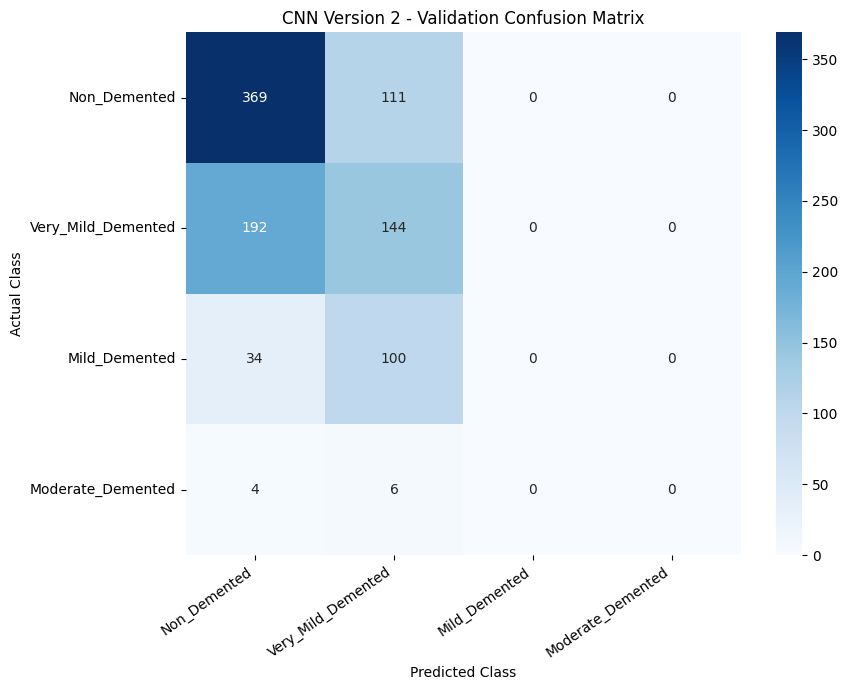


CNN VERSION 2 CLASSIFICATION REPORT
                    precision    recall  f1-score   support

      Non_Demented       0.62      0.77      0.68       480
Very_Mild_Demented       0.40      0.43      0.41       336
     Mild_Demented       0.00      0.00      0.00       134
 Moderate_Demented       0.00      0.00      0.00        10

          accuracy                           0.53       960
         macro avg       0.25      0.30      0.27       960
      weighted avg       0.45      0.53      0.49       960



In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Calculate confusion matrix
cm_v2 = confusion_matrix(
    actual_labels_v2,
    predicted_labels_v2,
    labels=[0, 1, 2, 3]
)

# Display confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_v2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Version 2 - Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Detailed classification metrics
print("\nCNN VERSION 2 CLASSIFICATION REPORT")
print("===================================")

print(
    classification_report(
        actual_labels_v2,
        predicted_labels_v2,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)

In [22]:
import numpy as np

print("AVERAGE PREDICTION PROBABILITIES BY ACTUAL CLASS")
print("================================================")

for actual_class_index, actual_class_name in enumerate(class_names):

    # Select validation images belonging to this actual class
    mask = actual_labels_v2 == actual_class_index

    # Average their predicted probabilities
    average_probs = np.mean(
        predicted_probabilities_v2[mask],
        axis=0
    )

    print(f"\nActual class: {actual_class_name}")
    print(f"Number of images: {np.sum(mask)}")

    for predicted_class_name, probability in zip(
        class_names,
        average_probs
    ):
        print(
            f"  {predicted_class_name}: "
            f"{probability * 100:.2f}%"
        )

AVERAGE PREDICTION PROBABILITIES BY ACTUAL CLASS

Actual class: Non_Demented
Number of images: 480
  Non_Demented: 53.67%
  Very_Mild_Demented: 28.62%
  Mild_Demented: 13.09%
  Moderate_Demented: 4.63%

Actual class: Very_Mild_Demented
Number of images: 336
  Non_Demented: 40.60%
  Very_Mild_Demented: 33.85%
  Mild_Demented: 19.77%
  Moderate_Demented: 5.78%

Actual class: Mild_Demented
Number of images: 134
  Non_Demented: 29.33%
  Very_Mild_Demented: 37.48%
  Mild_Demented: 26.54%
  Moderate_Demented: 6.64%

Actual class: Moderate_Demented
Number of images: 10
  Non_Demented: 33.41%
  Very_Mild_Demented: 35.37%
  Mild_Demented: 24.97%
  Moderate_Demented: 6.26%


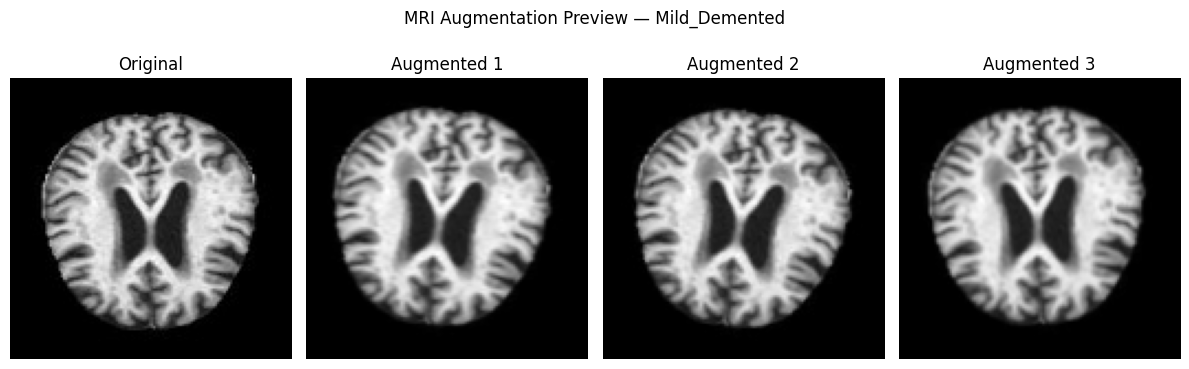

In [23]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Gentle augmentation for training images
data_augmentation_v3 = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomTranslation(
        height_factor=0.03,
        width_factor=0.03
    )
])

# Take one MRI image from the training dataset
for images, labels in train_dataset.take(1):
    sample_image = images[0]
    sample_label = int(labels[0].numpy())

# Generate augmented versions
plt.figure(figsize=(12, 4))

plt.subplot(1, 4, 1)
plt.imshow(sample_image.numpy().squeeze(), cmap="gray")
plt.title("Original")
plt.axis("off")

for i in range(3):
    augmented_image = data_augmentation_v3(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )

    plt.subplot(1, 4, i + 2)
    plt.imshow(augmented_image[0].numpy().squeeze(), cmap="gray")
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.suptitle(
    f"MRI Augmentation Preview — {class_names[sample_label]}"
)

plt.tight_layout()
plt.show()

In [24]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Create CNN Version 3
model_v3 = models.Sequential([

    layers.Input(shape=(128, 128, 1)),

    # Augmentation runs only during training
    data_augmentation_v3,

    # Convolutional Block 1
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),

    # Convolutional Block 2
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),

    # Convolutional Block 3
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),

    # Convolutional Block 4
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),

    # Preserve some spatial information
    layers.Flatten(),

    # Classification layers
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(4, activation="softmax")
])

# Compile Version 3
model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN VERSION 3 CREATED")
print("=====================")

model_v3.summary()

CNN VERSION 3 CREATED


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,290,884 (4.92 MB)

 Trainable params: 1,290,180 (4.92 MB)

 Non-trainable params: 704 (2.75 KB)

In [25]:
import os
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

# Google Drive folder for model checkpoints
model_save_dir = "/content/drive/MyDrive/Alzheimers_MRI_Project/models"

os.makedirs(model_save_dir, exist_ok=True)

# Save Version 3 separately
model_v3_save_path = os.path.join(
    model_save_dir,
    "best_custom_cnn_v3.keras"
)

# Stop training if validation loss stops improving
early_stopping_v3 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Save the best Version 3 model
model_checkpoint_v3 = ModelCheckpoint(
    filepath=model_v3_save_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Combine callbacks
callbacks_v3 = [
    early_stopping_v3,
    model_checkpoint_v3
]

print("CNN VERSION 3 CALLBACKS CONFIGURED")
print("==================================")

print("Version 3 save path:", model_v3_save_path)

print(
    "Original CNN preserved:",
    os.path.isfile(
        os.path.join(model_save_dir, "best_custom_cnn.keras")
    )
)

print(
    "CNN Version 2 preserved:",
    os.path.isfile(
        os.path.join(model_save_dir, "best_custom_cnn_v2.keras")
    )
)

print("Early stopping patience:", 5)

CNN VERSION 3 CALLBACKS CONFIGURED
Version 3 save path: /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v3.keras
Original CNN preserved: True
CNN Version 2 preserved: True
Early stopping patience: 5


In [26]:
# Train CNN Version 3
history_v3 = model_v3.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    class_weight=class_weights_v2,
    callbacks=callbacks_v3,
    verbose=1
)

print("\nCNN VERSION 3 TRAINING FINISHED")
print("==============================")

print(
    "Epochs completed:",
    len(history_v3.history["loss"])
)

print(
    "Best validation accuracy:",
    round(max(history_v3.history["val_accuracy"]) * 100, 2),
    "%"
)

print(
    "Best validation loss:",
    round(min(history_v3.history["val_loss"]), 4)
)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.3898 - loss: 1.7479
Epoch 1: val_loss improved from None to 7.72133, saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v3.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v3.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 52ms/step - accuracy: 0.4371 - loss: 1.2624 - val_accuracy: 0.0104 - val_loss: 7.7213
Epoch 2/15
139/140 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.4839 - loss: 1.0430
Epoch 2: val_loss improved from 7.72133 to 2.22486, saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v3.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v3.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.4757 - loss: 1.0438 - val_accuracy: 0.5000 - val_loss: 2.2249
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.4740 - 

In [27]:
import numpy as np
from collections import Counter

# Predict all validation MRI images
predicted_probabilities_v3 = model_v3.predict(
    val_dataset,
    verbose=1
)

# Convert probabilities into predicted class indices
predicted_labels_v3 = np.argmax(
    predicted_probabilities_v3,
    axis=1
)

# Count predictions for each class
prediction_counts_v3 = Counter(
    predicted_labels_v3
)

print("\nCNN VERSION 3 PREDICTION DISTRIBUTION")
print("=====================================")

for i, class_name in enumerate(class_names):
    print(
        f"{class_name}: "
        f"{prediction_counts_v3.get(i, 0)}"
    )

# Calculate validation accuracy
actual_labels_v3 = np.array(val_labels_encoded)

validation_accuracy_v3 = np.mean(
    predicted_labels_v3 == actual_labels_v3
)

print("\nTotal predictions:", len(predicted_labels_v3))

print(
    "Validation accuracy:",
    round(validation_accuracy_v3 * 100, 2),
    "%"
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step

CNN VERSION 3 PREDICTION DISTRIBUTION
Non_Demented: 514
Very_Mild_Demented: 410
Mild_Demented: 36
Moderate_Demented: 0

Total predictions: 960
Validation accuracy: 60.62 %


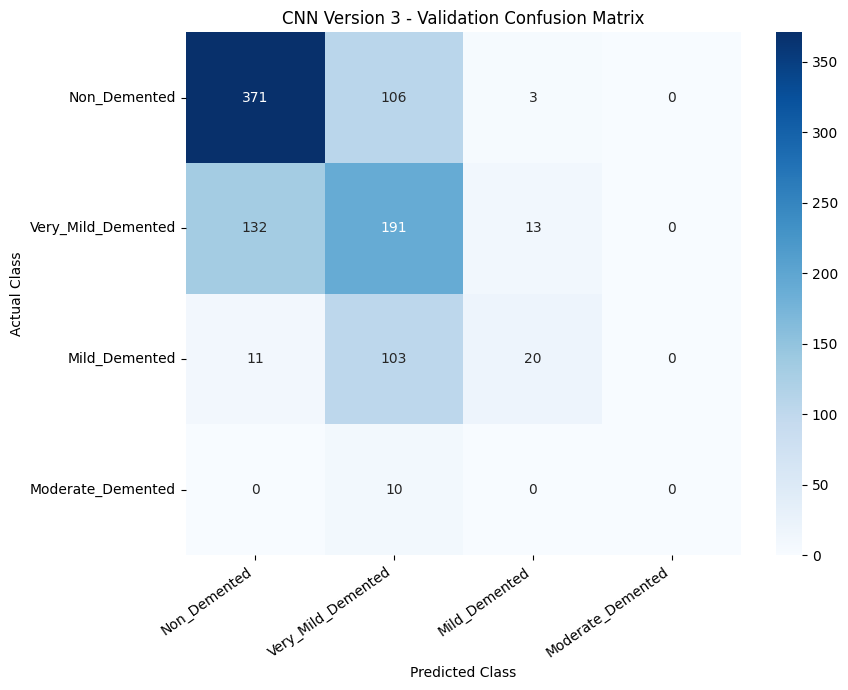


CNN VERSION 3 CLASSIFICATION REPORT
                    precision    recall  f1-score   support

      Non_Demented       0.72      0.77      0.75       480
Very_Mild_Demented       0.47      0.57      0.51       336
     Mild_Demented       0.56      0.15      0.24       134
 Moderate_Demented       0.00      0.00      0.00        10

          accuracy                           0.61       960
         macro avg       0.44      0.37      0.37       960
      weighted avg       0.60      0.61      0.59       960



In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Calculate confusion matrix
cm_v3 = confusion_matrix(
    actual_labels_v3,
    predicted_labels_v3,
    labels=[0, 1, 2, 3]
)

# Display confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_v3,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Version 3 - Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Generate classification report
print("\nCNN VERSION 3 CLASSIFICATION REPORT")
print("===================================")

print(
    classification_report(
        actual_labels_v3,
        predicted_labels_v3,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)

In [29]:
import numpy as np

print("CNN VERSION 3 - PROBABILITY ANALYSIS")
print("====================================")

for actual_class_index, actual_class_name in enumerate(class_names):

    # Select images belonging to this actual class
    mask = actual_labels_v3 == actual_class_index

    # Calculate average predicted probabilities
    average_probs = np.mean(
        predicted_probabilities_v3[mask],
        axis=0
    )

    print(f"\nActual class: {actual_class_name}")
    print("Number of images:", np.sum(mask))

    for predicted_class_name, probability in zip(
        class_names,
        average_probs
    ):
        print(
            f"  {predicted_class_name}: "
            f"{probability * 100:.2f}%"
        )

CNN VERSION 3 - PROBABILITY ANALYSIS

Actual class: Non_Demented
Number of images: 480
  Non_Demented: 67.35%
  Very_Mild_Demented: 24.35%
  Mild_Demented: 7.53%
  Moderate_Demented: 0.76%

Actual class: Very_Mild_Demented
Number of images: 336
  Non_Demented: 43.42%
  Very_Mild_Demented: 36.81%
  Mild_Demented: 18.05%
  Moderate_Demented: 1.73%

Actual class: Mild_Demented
Number of images: 134
  Non_Demented: 28.45%
  Very_Mild_Demented: 35.55%
  Mild_Demented: 31.92%
  Moderate_Demented: 4.07%

Actual class: Moderate_Demented
Number of images: 10
  Non_Demented: 24.73%
  Very_Mild_Demented: 29.20%
  Mild_Demented: 28.20%
  Moderate_Demented: 17.87%


In [30]:
from collections import Counter

# Count training images by class
train_class_counts = Counter(train_labels_encoded)

# Largest class size
largest_class_count = max(train_class_counts.values())

print("TRAINING CLASS IMBALANCE ANALYSIS")
print("=================================")

for i, class_name in enumerate(class_names):

    count = train_class_counts[i]

    ratio = largest_class_count / count

    print(f"\n{class_name}")
    print("  Training images:", count)
    print("  Imbalance ratio:", round(ratio, 2), ": 1")

print("\nTotal training images:", len(train_labels_encoded))

TRAINING CLASS IMBALANCE ANALYSIS

Non_Demented
  Training images: 2240
  Imbalance ratio: 1.0 : 1

Very_Mild_Demented
  Training images: 1568
  Imbalance ratio: 1.43 : 1

Mild_Demented
  Training images: 627
  Imbalance ratio: 3.57 : 1

Moderate_Demented
  Training images: 45
  Imbalance ratio: 49.78 : 1

Total training images: 4480


In [31]:
import numpy as np
from collections import Counter

# Reproducible random sampling
rng_v4 = np.random.default_rng(42)

# Original training data
train_paths_array = np.array(train_paths)
train_labels_array = np.array(train_labels_encoded)

# Target samples per class
target_counts_v4 = {
    0: 2240,  # Non_Demented
    1: 1568,  # Very_Mild_Demented
    2: 1000,  # Mild_Demented
    3: 400    # Moderate_Demented
}

oversampled_indices_v4 = []

for class_index, target_count in target_counts_v4.items():

    # Find original training samples for this class
    class_indices = np.where(
        train_labels_array == class_index
    )[0]

    # Keep all original samples
    selected_indices = list(class_indices)

    # Add randomly repeated samples when needed
    additional_count = target_count - len(class_indices)

    if additional_count > 0:
        additional_indices = rng_v4.choice(
            class_indices,
            size=additional_count,
            replace=True
        )

        selected_indices.extend(additional_indices.tolist())

    oversampled_indices_v4.extend(selected_indices)

# Shuffle the combined training list
oversampled_indices_v4 = np.array(oversampled_indices_v4)

rng_v4.shuffle(oversampled_indices_v4)

# Create Version 4 training paths and labels
train_paths_v4 = train_paths_array[oversampled_indices_v4]
train_labels_v4 = train_labels_array[oversampled_indices_v4]

# Verify the new distribution
counts_v4 = Counter(train_labels_v4)

print("CNN VERSION 4 - OVERSAMPLED TRAINING DATA")
print("=========================================")

for i, class_name in enumerate(class_names):
    print(f"{class_name}: {counts_v4[i]}")

print("\nOriginal training samples:", len(train_paths))
print("Oversampled training entries:", len(train_paths_v4))

print("\nValidation dataset: unchanged")
print("Test dataset: unchanged")

CNN VERSION 4 - OVERSAMPLED TRAINING DATA
Non_Demented: 2240
Very_Mild_Demented: 1568
Mild_Demented: 1000
Moderate_Demented: 400

Original training samples: 4480
Oversampled training entries: 5208

Validation dataset: unchanged
Test dataset: unchanged


In [32]:
import tensorflow as tf

# Create dataset from oversampled image paths and labels
train_dataset_v4 = tf.data.Dataset.from_tensor_slices(
    (train_paths_v4, train_labels_v4)
)

# Shuffle training entries
train_dataset_v4 = train_dataset_v4.shuffle(
    buffer_size=len(train_paths_v4),
    seed=42,
    reshuffle_each_iteration=True
)

# Load and normalize MRI images
train_dataset_v4 = train_dataset_v4.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Group images into batches
train_dataset_v4 = train_dataset_v4.batch(BATCH_SIZE)

# Improve data-loading performance
train_dataset_v4 = train_dataset_v4.prefetch(
    tf.data.AUTOTUNE
)

print("CNN VERSION 4 TRAINING DATASET CREATED")
print("======================================")

print("Total training entries:", len(train_paths_v4))
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_dataset_v4))

# Verify one batch
for images, labels in train_dataset_v4.take(1):
    print("\nImage batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", float(tf.reduce_min(images)))
    print("Maximum pixel value:", float(tf.reduce_max(images)))

print("\nOriginal validation dataset remains unchanged.")
print("Original test dataset remains untouched.")

CNN VERSION 4 TRAINING DATASET CREATED
Total training entries: 5208
Batch size: 32
Training batches: 163

Image batch shape: (32, 128, 128, 1)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0

Original validation dataset remains unchanged.
Original test dataset remains untouched.


In [33]:
import tensorflow as tf

# Create a fresh copy of the Version 3 architecture
model_v4 = tf.keras.models.clone_model(model_v3)

# Initialize fresh weights by building the model
model_v4.build(input_shape=(None, 128, 128, 1))

# Compile Version 4
model_v4.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN VERSION 4 MODEL CREATED")
print("===========================")

print("\nVersion 4 model summary:")
model_v4.summary()

print("\nTotal parameters:", model_v4.count_params())

print("\nVersion 4 uses:")
print("- Same CNN architecture as Version 3")
print("- Freshly initialized model weights")
print("- Gentle MRI augmentation")
print("- Batch normalization")
print("- Dropout regularization")
print("- Learning rate: 0.0003")
print("- Partial oversampling during training")

CNN VERSION 4 MODEL CREATED

Version 4 model summary:


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,290,884 (4.92 MB)

 Trainable params: 1,290,180 (4.92 MB)

 Non-trainable params: 704 (2.75 KB)


Total parameters: 1290884

Version 4 uses:
- Same CNN architecture as Version 3
- Freshly initialized model weights
- Gentle MRI augmentation
- Batch normalization
- Dropout regularization
- Learning rate: 0.0003
- Partial oversampling during training


In [34]:
import os
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Folder containing saved CNN models
model_save_dir = "/content/drive/MyDrive/Alzheimers_MRI_Project/models"

os.makedirs(model_save_dir, exist_ok=True)

# Separate checkpoint for CNN Version 4
model_v4_save_path = os.path.join(
    model_save_dir,
    "best_custom_cnn_v4.keras"
)

# Stop if validation loss stops improving
early_stopping_v4 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Save the best model automatically
model_checkpoint_v4 = ModelCheckpoint(
    filepath=model_v4_save_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Combine callbacks
callbacks_v4 = [
    early_stopping_v4,
    model_checkpoint_v4
]

print("CNN VERSION 4 CALLBACKS CONFIGURED")
print("==================================")

print("Version 4 save path:", model_v4_save_path)

print("\nPrevious checkpoints:")

for version in ["", "_v2", "_v3"]:
    filename = f"best_custom_cnn{version}.keras"
    filepath = os.path.join(model_save_dir, filename)

    print(filename, ":", os.path.isfile(filepath))

print("\nEarly stopping patience:", 5)
print("Checkpoint monitor: val_loss")

CNN VERSION 4 CALLBACKS CONFIGURED
Version 4 save path: /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v4.keras

Previous checkpoints:
best_custom_cnn.keras : True
best_custom_cnn_v2.keras : True
best_custom_cnn_v3.keras : True

Early stopping patience: 5
Checkpoint monitor: val_loss


In [35]:
# Train CNN Version 4 using partially oversampled data

history_v4 = model_v4.fit(
    train_dataset_v4,
    validation_data=val_dataset,
    epochs=15,
    callbacks=callbacks_v4,
    verbose=1
)

print("\nCNN VERSION 4 TRAINING FINISHED")
print("================================")

print(
    "Epochs completed:",
    len(history_v4.history["loss"])
)

print(
    "Best validation accuracy:",
    round(max(history_v4.history["val_accuracy"]) * 100, 2),
    "%"
)

print(
    "Best validation loss:",
    round(min(history_v4.history["val_loss"]), 4)
)

Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.4177 - loss: 1.7203
Epoch 1: val_loss improved from None to 3.03483, saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v4.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v4.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 16s 58ms/step - accuracy: 0.4399 - loss: 1.2912 - val_accuracy: 0.3500 - val_loss: 3.0348
Epoch 2/15
162/163 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.4724 - loss: 1.1197
Epoch 2: val_loss improved from 3.03483 to 1.42178, saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v4.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Alzheimers_MRI_Project/models/best_custom_cnn_v4.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - accuracy: 0.4595 - loss: 1.1269 - val_accuracy: 0.5188 - val_loss: 1.4218
Epoch 3/15
162/163 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.4676 - 

In [36]:
import tensorflow as tf
import numpy as np
from collections import Counter

# Load the best saved Version 4 checkpoint
best_model_v4 = tf.keras.models.load_model(
    model_v4_save_path
)

# Predict validation MRI images
predicted_probabilities_v4 = best_model_v4.predict(
    val_dataset,
    verbose=1
)

# Convert probabilities into predicted class labels
predicted_labels_v4 = np.argmax(
    predicted_probabilities_v4,
    axis=1
)

# Count predictions for each class
prediction_counts_v4 = Counter(
    predicted_labels_v4
)

print("\nCNN VERSION 4 - SAVED CHECKPOINT")
print("================================")

print("Checkpoint selected by: lowest validation loss")
print("Best checkpoint epoch: 11")

print("\nPREDICTION DISTRIBUTION")
print("=======================")

for i, class_name in enumerate(class_names):
    print(
        f"{class_name}: "
        f"{prediction_counts_v4.get(i, 0)}"
    )

# Calculate accuracy against actual validation labels
actual_labels_v4 = np.array(val_labels_encoded)

validation_accuracy_v4 = np.mean(
    predicted_labels_v4 == actual_labels_v4
)

print("\nTotal predictions:", len(predicted_labels_v4))

print(
    "Saved checkpoint validation accuracy:",
    round(validation_accuracy_v4 * 100, 2),
    "%"
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step

CNN VERSION 4 - SAVED CHECKPOINT
Checkpoint selected by: lowest validation loss
Best checkpoint epoch: 11

PREDICTION DISTRIBUTION
Non_Demented: 532
Very_Mild_Demented: 286
Mild_Demented: 142
Moderate_Demented: 0

Total predictions: 960
Saved checkpoint validation accuracy: 64.69 %


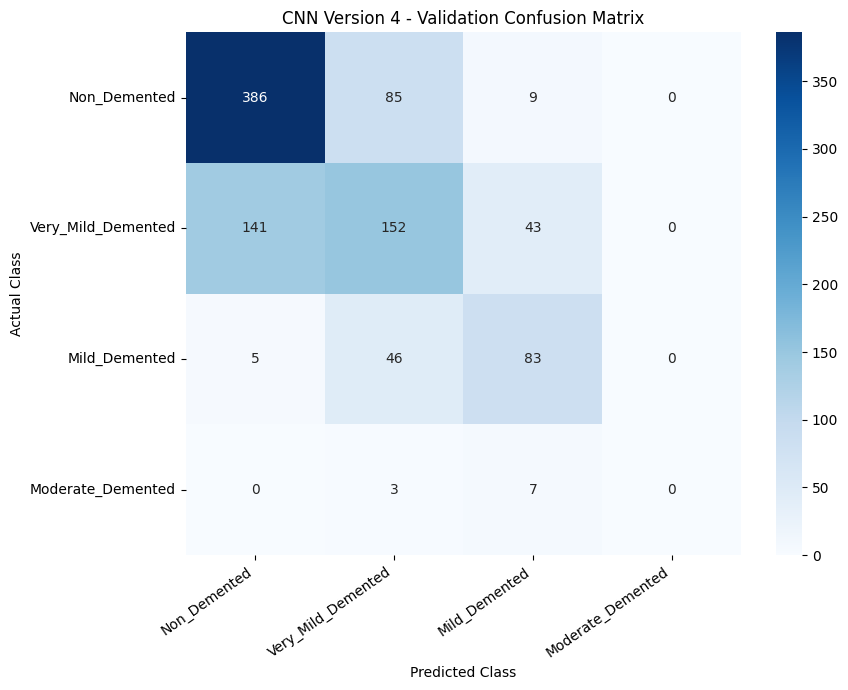


CNN VERSION 4 CLASSIFICATION REPORT
                    precision    recall  f1-score   support

      Non_Demented       0.73      0.80      0.76       480
Very_Mild_Demented       0.53      0.45      0.49       336
     Mild_Demented       0.58      0.62      0.60       134
 Moderate_Demented       0.00      0.00      0.00        10

          accuracy                           0.65       960
         macro avg       0.46      0.47      0.46       960
      weighted avg       0.63      0.65      0.64       960



In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Calculate confusion matrix for saved Version 4 model
cm_v4 = confusion_matrix(
    actual_labels_v4,
    predicted_labels_v4,
    labels=[0, 1, 2, 3]
)

# Display confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_v4,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Version 4 - Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Generate classification report
print("\nCNN VERSION 4 CLASSIFICATION REPORT")
print("===================================")

print(
    classification_report(
        actual_labels_v4,
        predicted_labels_v4,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)

In [38]:
import numpy as np

# Select actual Moderate_Demented validation images
moderate_mask_v4 = actual_labels_v4 == 3

# Get predictions and probabilities for these images
moderate_predictions_v4 = predicted_labels_v4[moderate_mask_v4]

moderate_probabilities_v4 = predicted_probabilities_v4[
    moderate_mask_v4
]

print("CNN VERSION 4 - MODERATE DEMENTIA ANALYSIS")
print("==========================================")

print(
    "Actual Moderate_Demented images:",
    len(moderate_predictions_v4)
)

print("\nPredicted classes:")

for i, class_name in enumerate(class_names):
    count = np.sum(moderate_predictions_v4 == i)
    print(f"{class_name}: {count}")

print("\nAverage predicted probabilities:")

average_moderate_probs_v4 = np.mean(
    moderate_probabilities_v4,
    axis=0
)

for class_name, probability in zip(
    class_names,
    average_moderate_probs_v4
):
    print(f"{class_name}: {probability * 100:.2f}%")

print("\nIndividual Moderate_Demented predictions:")
print("=========================================")

for i, (prediction, probabilities) in enumerate(
    zip(moderate_predictions_v4, moderate_probabilities_v4),
    start=1
):
    print(
        f"Image {i}: "
        f"Predicted = {class_names[prediction]}, "
        f"Moderate probability = {probabilities[3] * 100:.2f}%"
    )

CNN VERSION 4 - MODERATE DEMENTIA ANALYSIS
Actual Moderate_Demented images: 10

Predicted classes:
Non_Demented: 0
Very_Mild_Demented: 3
Mild_Demented: 7
Moderate_Demented: 0

Average predicted probabilities:
Non_Demented: 25.01%
Very_Mild_Demented: 29.25%
Mild_Demented: 29.90%
Moderate_Demented: 15.83%

Individual Moderate_Demented predictions:
Image 1: Predicted = Mild_Demented, Moderate probability = 12.94%
Image 2: Predicted = Mild_Demented, Moderate probability = 15.07%
Image 3: Predicted = Mild_Demented, Moderate probability = 21.33%
Image 4: Predicted = Very_Mild_Demented, Moderate probability = 10.28%
Image 5: Predicted = Very_Mild_Demented, Moderate probability = 14.99%
Image 6: Predicted = Mild_Demented, Moderate probability = 9.80%
Image 7: Predicted = Very_Mild_Demented, Moderate probability = 24.90%
Image 8: Predicted = Mild_Demented, Moderate probability = 13.85%
Image 9: Predicted = Mild_Demented, Moderate probability = 12.01%
Image 10: Predicted = Mild_Demented, Moderat

In [39]:
import pandas as pd

# Validation results from completed experiments
experiment_results = pd.DataFrame({
    "Model": [
        "CNN Version 2",
        "CNN Version 3",
        "CNN Version 4"
    ],
    "Validation Accuracy (%)": [
        53.44,
        60.62,
        64.69
    ],
    "Macro F1": [
        0.27,
        0.37,
        0.46
    ],
    "Mild Recall (%)": [
        0,
        15,
        62
    ],
    "Moderate Recall (%)": [
        0,
        0,
        0
    ],
    "Training Strategy": [
        "Moderated class weights",
        "Augmentation + class weights",
        "Augmentation + partial oversampling"
    ]
})

print("ALZHEIMER MRI - CNN EXPERIMENT COMPARISON")
print("========================================")

display(experiment_results)

# Save results to Google Drive
results_path = (
    "/content/drive/MyDrive/"
    "Alzheimers_MRI_Project/"
    "cnn_experiment_comparison.csv"
)

experiment_results.to_csv(
    results_path,
    index=False
)

print("\nResults saved to:", results_path)

ALZHEIMER MRI - CNN EXPERIMENT COMPARISON


,Model,Validation Accuracy (%),Macro F1,Mild Recall (%),Moderate Recall (%),Training Strategy
0,CNN Version 2,53.44,0.27,0,0,Moderated class weights
1,CNN Version 3,60.62,0.37,15,0,Augmentation + class weights
2,CNN Version 4,64.69,0.46,62,0,Augmentation + partial oversampling



Results saved to: /content/drive/MyDrive/Alzheimers_MRI_Project/cnn_experiment_comparison.csv


In [40]:
import os

project_dir = "/content/drive/MyDrive/Alzheimers_MRI_Project"

files_to_check = {
    "CNN Version 1": "models/best_custom_cnn.keras",
    "CNN Version 2": "models/best_custom_cnn_v2.keras",
    "CNN Version 3": "models/best_custom_cnn_v3.keras",
    "CNN Version 4": "models/best_custom_cnn_v4.keras",
    "Experiment comparison": "cnn_experiment_comparison.csv"
}

print("ALZHEIMER MRI PROJECT - SAVED FILE VERIFICATION")
print("===============================================")

all_files_present = True

for description, relative_path in files_to_check.items():

    full_path = os.path.join(project_dir, relative_path)
    exists = os.path.isfile(full_path)

    status = "FOUND" if exists else "MISSING"

    print(f"{description}: {status}")

    if not exists:
        all_files_present = False

print("\nAll required files saved:", all_files_present)

ALZHEIMER MRI PROJECT - SAVED FILE VERIFICATION
CNN Version 1: FOUND
CNN Version 2: FOUND
CNN Version 3: FOUND
CNN Version 4: FOUND
Experiment comparison: FOUND

All required files saved: True


In [41]:
import tensorflow as tf
import numpy as np

# Create the test dataset using the original test split
test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels_encoded)
)

# Load and normalize MRI images
test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Create batches without shuffling
test_dataset = test_dataset.batch(BATCH_SIZE)

# Improve loading performance
test_dataset = test_dataset.prefetch(
    tf.data.AUTOTUNE
)

print("FINAL TEST DATASET PREPARED")
print("===========================")

print("Total test images:", len(test_paths))
print("Batch size:", BATCH_SIZE)
print("Number of test batches:", len(test_dataset))

print("\nTest class distribution:")

for i, class_name in enumerate(class_names):
    count = np.sum(np.array(test_labels_encoded) == i)
    print(f"{class_name}: {count}")

# Verify the first batch
for images, labels in test_dataset.take(1):
    print("\nImage batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel minimum:", float(tf.reduce_min(images)))
    print("Pixel maximum:", float(tf.reduce_max(images)))

FINAL TEST DATASET PREPARED
Total test images: 960
Batch size: 32
Number of test batches: 30

Test class distribution:
Non_Demented: 480
Very_Mild_Demented: 336
Mild_Demented: 135
Moderate_Demented: 9

Image batch shape: (32, 128, 128, 1)
Label batch shape: (32,)
Pixel minimum: 0.0
Pixel maximum: 1.0


In [42]:
import tensorflow as tf
import numpy as np

# Load the best saved CNN Version 4 model
final_model = tf.keras.models.load_model(
    model_v4_save_path
)

print("FINAL CNN VERSION 4 - TEST EVALUATION")
print("=====================================")

# Evaluate on the untouched test dataset
test_loss, test_accuracy = final_model.evaluate(
    test_dataset,
    verbose=1
)

print("\nFINAL TEST RESULTS")
print("==================")

print(
    "Test accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)

print(
    "Test loss:",
    round(test_loss, 4)
)

print("\nValidation accuracy of selected checkpoint: 64.69%")
print("Test images evaluated:", len(test_paths))

FINAL CNN VERSION 4 - TEST EVALUATION
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.6240 - loss: 0.7367

FINAL TEST RESULTS
Test accuracy: 62.4 %
Test loss: 0.7367

Validation accuracy of selected checkpoint: 64.69%
Test images evaluated: 960


30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


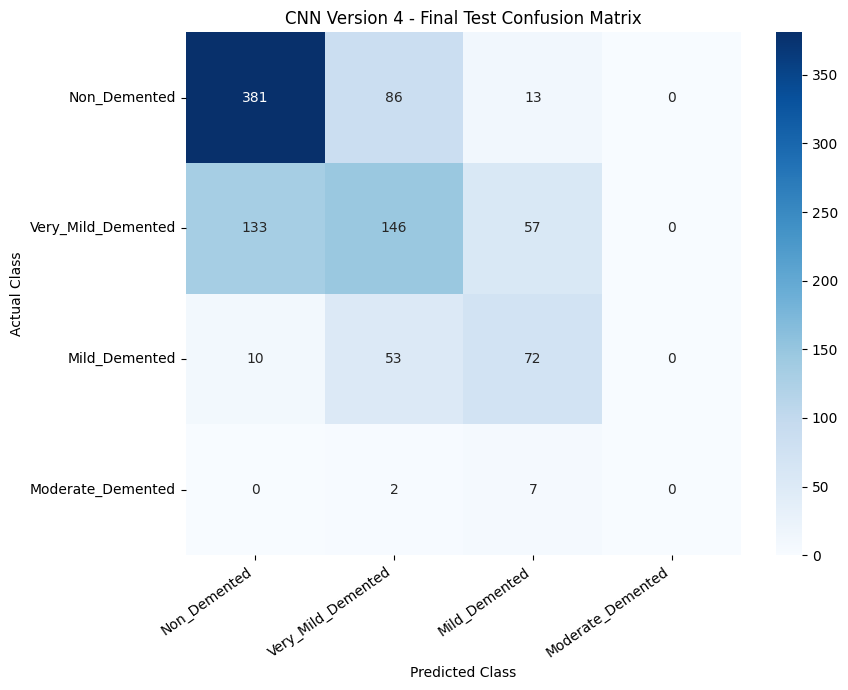


CNN VERSION 4 - FINAL TEST CLASSIFICATION REPORT
                    precision    recall  f1-score   support

      Non_Demented       0.73      0.79      0.76       480
Very_Mild_Demented       0.51      0.43      0.47       336
     Mild_Demented       0.48      0.53      0.51       135
 Moderate_Demented       0.00      0.00      0.00         9

          accuracy                           0.62       960
         macro avg       0.43      0.44      0.43       960
      weighted avg       0.61      0.62      0.61       960



In [43]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Predict probabilities for all test MRI images
test_probabilities_v4 = final_model.predict(
    test_dataset,
    verbose=1
)

# Convert probabilities into predicted class labels
test_predictions_v4 = np.argmax(
    test_probabilities_v4,
    axis=1
)

# Actual test labels
actual_test_labels = np.array(
    test_labels_encoded
)

# Calculate confusion matrix
test_cm_v4 = confusion_matrix(
    actual_test_labels,
    test_predictions_v4,
    labels=[0, 1, 2, 3]
)

# Display confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    test_cm_v4,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Version 4 - Final Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Display classification report
print("\nCNN VERSION 4 - FINAL TEST CLASSIFICATION REPORT")
print("================================================")

print(
    classification_report(
        actual_test_labels,
        test_predictions_v4,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)

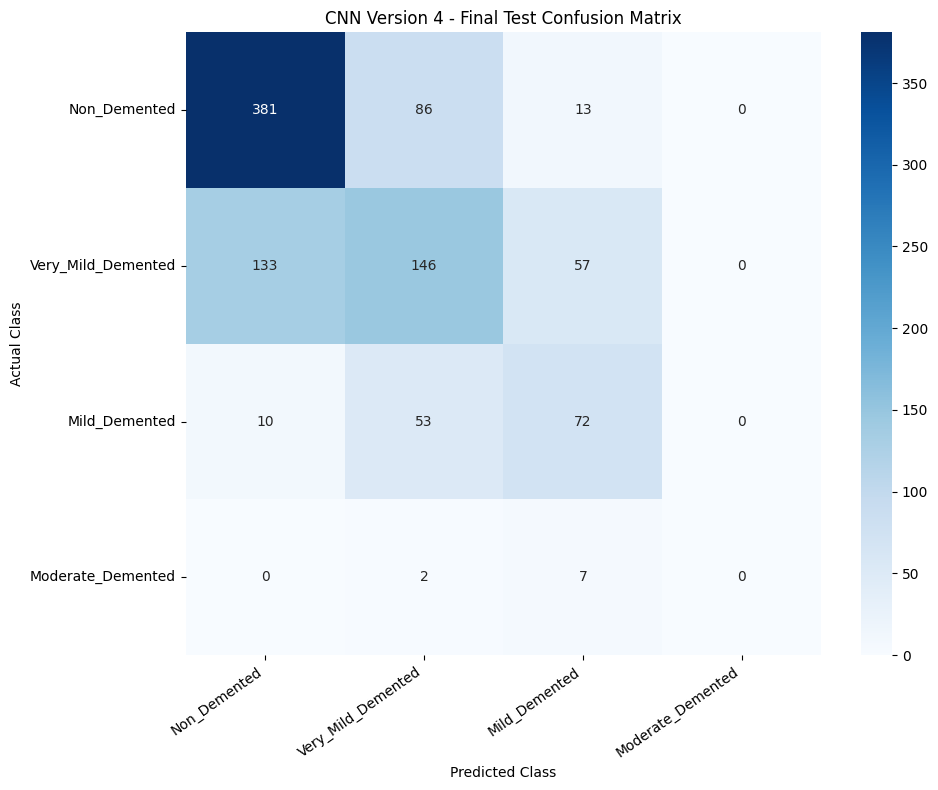


FINAL TEST RESULTS SAVED
Classification report: /content/drive/MyDrive/Alzheimers_MRI_Project/results/cnn_v4_test_classification_report.csv
Confusion matrix CSV: /content/drive/MyDrive/Alzheimers_MRI_Project/results/cnn_v4_test_confusion_matrix.csv
Confusion matrix image: /content/drive/MyDrive/Alzheimers_MRI_Project/results/cnn_v4_test_confusion_matrix.png

All files saved successfully: True


In [44]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report

# Create results folder in Google Drive
results_dir = (
    "/content/drive/MyDrive/"
    "Alzheimers_MRI_Project/results"
)

os.makedirs(results_dir, exist_ok=True)

# Generate detailed classification report
report_dict = classification_report(
    actual_test_labels,
    test_predictions_v4,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

# Save classification report as CSV
report_df = pd.DataFrame(report_dict).transpose()

report_path = os.path.join(
    results_dir,
    "cnn_v4_test_classification_report.csv"
)

report_df.to_csv(report_path)

# Save confusion matrix as CSV
cm_df = pd.DataFrame(
    test_cm_v4,
    index=class_names,
    columns=class_names
)

cm_path = os.path.join(
    results_dir,
    "cnn_v4_test_confusion_matrix.csv"
)

cm_df.to_csv(cm_path)

# Save confusion matrix as an image
plt.figure(figsize=(10, 8))

sns.heatmap(
    test_cm_v4,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Version 4 - Final Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

image_path = os.path.join(
    results_dir,
    "cnn_v4_test_confusion_matrix.png"
)

plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nFINAL TEST RESULTS SAVED")
print("========================")

print("Classification report:", report_path)
print("Confusion matrix CSV:", cm_path)
print("Confusion matrix image:", image_path)

print("\nAll files saved successfully:",
      all(os.path.isfile(p) for p in [
          report_path, cm_path, image_path
      ]))

In [45]:
import os

summary_path = os.path.join(
    results_dir,
    "project_results_summary.txt"
)

summary_text = """
ALZHEIMER'S DISEASE DETECTION AND STAGE CLASSIFICATION
FROM BRAIN MRI IMAGES USING DEEP LEARNING

PROJECT TYPE
Academic deep-learning prototype

DATASET
Total MRI images: 6400
Image dimensions: 128 x 128 x 1
Number of classes: 4

CLASSES
1. Non_Demented
2. Very_Mild_Demented
3. Mild_Demented
4. Moderate_Demented

DATA SPLIT
Training: 4480 images (70%)
Validation: 960 images (15%)
Testing: 960 images (15%)

MODEL EXPERIMENTS
CNN Version 1: Interrupted training; incomplete baseline
CNN Version 2: Validation accuracy 53.44%, Macro F1 0.27
CNN Version 3: Validation accuracy 60.62%, Macro F1 0.37
CNN Version 4: Validation accuracy 64.69%, Macro F1 0.46

SELECTED MODEL
CNN Version 4
Selection based on validation performance
Architecture: Custom CNN with batch normalization,
dropout and gentle data augmentation
Training strategy: Partial minority-class oversampling
Checkpoint selected by lowest validation loss (Epoch 11)

FINAL TEST RESULTS
Test accuracy: 62.40%
Test loss: 0.7367
Macro precision: 0.43
Macro recall: 0.44
Macro F1-score: 0.43
Weighted F1-score: 0.61

TEST RECALL BY CLASS
Non_Demented: 79%
Very_Mild_Demented: 43%
Mild_Demented: 53%
Moderate_Demented: 0%

IMPORTANT LIMITATIONS
1. Severe class imbalance, especially Moderate_Demented.
2. Only 45 distinct Moderate_Demented training images.
3. No Moderate_Demented test images correctly classified.
4. Patient-independent splitting could not be verified
   because patient identifiers were unavailable.
5. Results are from an academic prototype and are not
   suitable for clinical diagnosis.

FINAL TEST SET
960 held-out MRI images.
The test set was not used for model training or selection.
"""

with open(summary_path, "w", encoding="utf-8") as file:
    file.write(summary_text.strip() + "\n")

print("PROJECT RESULTS SUMMARY SAVED")
print("=============================")
print("File:", summary_path)
print("File exists:", os.path.isfile(summary_path))
print("File size:", os.path.getsize(summary_path), "bytes")

PROJECT RESULTS SUMMARY SAVED
File: /content/drive/MyDrive/Alzheimers_MRI_Project/results/project_results_summary.txt
File exists: True
File size: 1666 bytes
